# LoRA through the decomposition: is a LoRA update easier to commute past the VPD decomposition than a full-weight fine-tune?

Results in `experiments/lora_commute/results/lora_commute.json` (predictions filed before the run in `results/predictions.json`;
scoring and every number in `reports/analyses/2026-10-19_analysis_lora-commute.md`). Plan: `reports/plans/2026-10-19_plan_lora-lift-and-pullback.md` and its addendum.

**The question (user, 2026-10-19).** "I want to see if it's easier / works better to decompose a LoRA update than it is a normal
fine-tuning update (my instinct says yes). I want to test this on pull-back, lift and whatever other methods we have tried so far."

**What was run.** The emoticon → `o` behaviour, learned four ways on the released 67M model, each update then put through the
decomposition with the same maps and measured the same way on the 73 held-out windows:

| update | map | arms |
|---|---|---|
| LoRA of rank r ∈ {1, 4, 8, 32} on `h.2.mlp.down_proj` (the paper's LoRA site) | do-nothing (δW in Δ); **lift** (Euclidean lift of the finished δW onto that matrix's 358 alive subcomponents) | `LoRA_r nothing`, `lift_r`, at the scored step (first checkpoint with P(o) ≥ 0.9: 30 for rank 1, 10 otherwise) and at step 100 |
| full-weight fine-tune on all 24 matrices (arm A, Adam) | do-nothing; **lift** on all 24 matrices (round 2's lift) | `ft nothing`, `ft lift`, at steps 10 and 100 |
| none (the subcomponents are trained directly) | **pull-back** confined to the LoRA's matrix with LoRA-shaped (rank-r) offsets; free offsets on that matrix; free offsets on all 24 matrices (the ladder's arm) | `pb_r`, `pb_full`, `pb_all`, scored at step 30 |

**Terms.** *Lift*: write the finished weight change M as the minimum-norm change (dU, dV) to the alive subcomponents of its matrix
with dU Vᵀ + U dVᵀ = M − O(M); the rest, O(M) − dU dVᵀ, goes to Δ. *Pull-back*: train the subcomponents' (U, V) on the fine-tune
loss with Γ and Δ fixed. *Inexpressible share*: the share of the update's output energy (inputs weighted by E[a aᵀ] over the
training windows) that no first-order change of the alive subcomponents can express; its *null* is the same share for an isotropic
update. *Route split* (`local_faith.route_split`): the held-out log-odds gain of `o` at the trigger split into d (changed
subcomponents at W₀'s CI values), r (changed CI values on the unchanged subcomponents), i (interaction), e_gate (subcomponents Γ
masks off) and e_Δ (not in the subcomponents at all); they sum to 1. *Pile ratios*: round 2's faithfulness harness (2 × 128 Pile val
rows; stochastic, CI-masked, unmasked and PGD KL), each divided by W₀'s value under the same adversary seed.

**Two readings (user, 2026-10-19).** *Reading A*, the weak version in `GOALS.md` as written: the updated decomposition is faithful to
W + δW under VPD's own checks, with Δ not absorbing the update. That is read first: the PGD ratios against the W₀ floor, the
inexpressible share, e_Δ and the Pile ratios. The direct share d is a *mechanism* reading (where the behaviour routes), not a pass
criterion, even where a filed prediction names it.

**Provenance note.** The pod was terminated after the run finished but before the final JSON was downloaded; `pb_r32`, `pb_full`,
`pb_all`, the seed arms, the score and the W₀ task-local seeds were rebuilt from the run's own log by `experiments/lora_commute/recover.py`
(flagged `recovered_from_log`; their per-step curves and task-local harness numbers are lost). Run time 37 min on one RTX 4090.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

R = Path('../experiments/lora_commute/results')
res = json.loads((R / 'lora_commute.json').read_text())
pred = json.loads((R / 'predictions.json').read_text())
S, L, PB, FT, SC = res['sizes'], res['lora'], res['pb'], res['ft'], res['score']
W0 = res['W0']
FLOOR = 1 + 3 * W0['pgd_floor']           # Pile PGD: W0 + 3 floors (3-seed spread)
C = {'blue': '#2a78d6', 'orange': '#eb6834', 'aqua': '#1baf7a', 'yellow': '#eda100', 'magenta': '#e87ba4',
     'green': '#008300', 'violet': '#6250d6', 'gray': '#8a8a86'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.titlesize': 11, 'font.size': 9, 'legend.fontsize': 8})

def lora_rec(r, step=None):
    a = L[str(r)]
    return a['steps'][str(step or a['scored_step'])]

rows = []
def add(name, rec, p_o=None, kl_other=None, step=None, inex=None):
    s, pc = rec['routes']['shares'], rec['routes']['p_cells']
    loc = rec.get('local')
    rows.append({'arm': name, 'step': step, 'P(o)': p_o if p_o is not None else pc['T1'], 'kl_other': kl_other,
                 'P(o) components only': pc['U1'], 'd': s['d'], 'r': s['r'], 'i': s['i'], 'e_gate': s['e_gate'], 'e_delta': s['e_delta'],
                 'inexpressible': inex, 'Delta change': rec['delta_change_frac'],
                 **({f'pile {k}': rec['pile'][k] for k in ('stochastic_kl', 'ci_masked_kl', 'pgd_kl')} if 'pile' in rec else {}),
                 'local pgd_trigger': None if loc is None else loc['pgd_trigger']['kl_trigger'] / W0['base']['pgd_trigger']['kl_trigger'],
                 'local pgd_all': None if loc is None else loc['pgd_all']['kl_trigger'] / W0['base']['pgd_all']['kl_trigger'],
                 'moved': rec.get('moved', {}).get('n_moved'), 'recovered': rec.get('recovered_from_log', False)})

for step in S['ft_ckpts']:
    st, ev = FT['steps'][str(step)], FT['evals'][str(step)]
    add(f'ft nothing', st['nothing'], ev['p_o'], ev['kl_other'], step, st['inexpressible']['pooled'])
    add(f'ft lift', st['lift'], ev['p_o'], ev['kl_other'], step, st['inexpressible']['pooled'])
for r in S['ranks']:
    a = L[str(r)]
    for step in sorted({a['scored_step'], 100}):
        st, ev = a['steps'][str(step)], a['evals'][str(step)]
        add(f'LoRA_{r} nothing', st['nothing'], ev['p_o'], ev['kl_other'], step, st['inexpressible']['pooled'])
        add(f'lift_{r}', st['lift'], ev['p_o'], ev['kl_other'], step, st['inexpressible']['pooled'])
for name, a in PB.items():
    sel = a['sweep'][f"{a['selected_lr']:g}"]
    add(name, a['steps'][str(S['pb_steps'])], sel['p_o'], sel['kl_other'], S['pb_steps'], 0.0)
T = pd.DataFrame(rows)
def is_scored_row(x):
    if x.arm.startswith('ft'): return x.step == 10
    if x.arm.startswith('pb'): return True
    return x.step == L[x.arm.split('_')[1].split(' ')[0]]['scored_step']
scored = T[T.apply(is_scored_row, axis=1)].copy()
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
print(f"Pile PGD floor at W0 (3 adversary seeds): ratio spread {W0['pgd_floor']:.3f}; W0 + 3 floors = {FLOOR:.3f}")
scored.set_index(['arm', 'step']).round(3)

Pile PGD floor at W0 (3 adversary seeds): ratio spread 0.035; W0 + 3 floors = 1.106


,,P(o),kl_other,P(o) components only,d,r,i,e_gate,e_delta,inexpressible,Delta change,pile stochastic_kl,pile ci_masked_kl,pile pgd_kl,local pgd_trigger,local pgd_all,moved,recovered
arm,step,,,,,,,,,,,,,,,,,
ft nothing,10,0.999,0.053,0.012,0.000,0.596,-0.000,-0.596,1.000,0.268,1.000,1.003,0.998,2.488,1.518,1.700,NaN,False
ft lift,10,0.999,0.053,0.998,0.053,0.596,-0.000,0.265,0.085,0.268,0.360,1.003,0.997,7.310,1.976,1.732,2757.0,False
LoRA_1 nothing,30,0.994,0.038,0.012,0.000,0.585,-0.000,-0.585,1.000,0.403,1.000,NaN,NaN,NaN,1.794,1.735,NaN,False
lift_1,30,0.994,0.038,0.858,0.077,0.585,-0.012,-0.060,0.410,0.403,0.486,1.009,1.009,1.457,1.670,1.732,321.0,False
LoRA_4 nothing,10,0.974,0.047,0.012,0.000,0.593,0.000,-0.593,1.000,0.427,1.000,NaN,NaN,NaN,1.619,1.916,NaN,False
lift_4,10,0.974,0.047,0.736,0.067,0.593,-0.007,-0.082,0.429,0.427,0.480,1.003,1.002,1.347,1.835,1.956,322.0,False
LoRA_8 nothing,10,0.999,0.154,0.012,0.000,0.540,0.000,-0.540,1.000,0.411,1.000,1.029,1.038,1.394,1.991,2.377,NaN,False
lift_8,10,0.999,0.154,0.953,0.072,0.540,-0.007,-0.008,0.404,0.411,0.491,1.026,1.035,2.017,1.900,2.268,340.0,False
LoRA_32 nothing,10,0.997,0.038,0.012,0.000,0.586,0.000,-0.586,1.000,0.385,1.000,NaN,NaN,NaN,1.622,1.767,NaN,False


Every arm learned the behaviour (held-out P(o) 0.93 to 1.00; the scored-step rule put rank 1 at step 30). Gates as filed:
G1 all learned, G2 (the lifted state's target model has the fine-tune's P(o) to 1e-3, shares sum to 1) holds for every lift, the
seed floor gives m = 0.115. G4 reproduced the ladder's `pb_all` shares (d 0.025 vs 0.025, r 0.53 vs 0.53) and the recruit test's
LoRA_8 do-nothing r (0.54 vs 0.54) exactly, and round 2's do-nothing Pile PGD ratio within 25% (2.49 vs 2.18), but **missed on the
full-weight lift's Pile PGD ratio: 7.31 against round 2's 5.41** (+35%). Everything else about that state reproduces to three or four
digits or within a few percent (the fine-tune's kl_other within 4%, its norm within 1%, P(o) 0.9993 in both; W₀'s four Pile numbers
and the lift's Δ-change fraction 0.3595 vs 0.3596 to four digits; the unmasked ratio 1.205 vs 1.20), so the miss is in the 20-step
adversarial search on a different GPU (RTX 4090 here, L40 then), not in the state. The cause is not established (the pod is gone); the ordering lift ≫ do-nothing > floor is the same in both runs, and
every PGD number below should be read with that ±35% in mind.

## 1. Reading A: is the updated decomposition faithful to W + δW under VPD's own checks? (Pile harness)

The three Pile ratios per arm (stochastic, CI-masked, PGD; each ÷ W₀ under the same adversary seed). The green line is W₀ + 3 floors
(the 3-seed spread of W₀'s PGD KL is 3.5%); the red line is the 1.5 that round 2's and this round's predictions call "breaks".

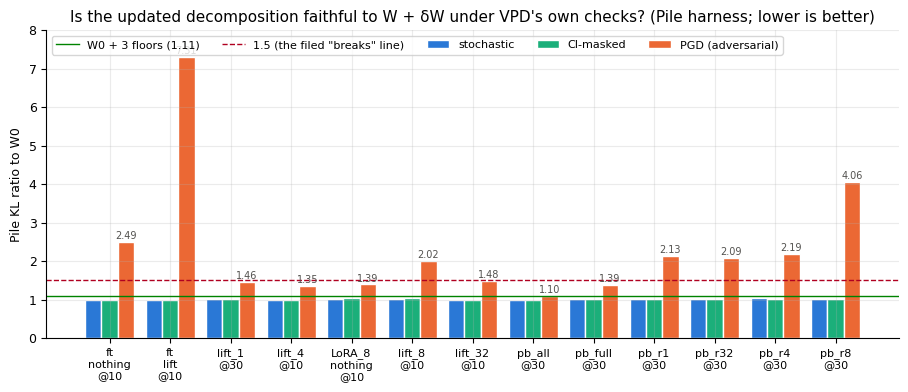

In [2]:
fig, ax = plt.subplots(figsize=(11, 4))
P = scored[scored['pile pgd_kl'].notna()].reset_index(drop=True)
x = np.arange(len(P)); w = 0.27
for j, (k, col, lab) in enumerate((('pile stochastic_kl', C['blue'], 'stochastic'), ('pile ci_masked_kl', C['aqua'], 'CI-masked'), ('pile pgd_kl', C['orange'], 'PGD (adversarial)'))):
    ax.bar(x + (j - 1) * w, P[k], w, color=col, label=lab, edgecolor='white', linewidth=1)
ax.axhline(FLOOR, color=C['green'], lw=1, label=f'W0 + 3 floors ({FLOOR:.2f})')
ax.axhline(1.5, color='#b00020', lw=1, ls='--', label='1.5 (the filed "breaks" line)')
for i, v in enumerate(P['pile pgd_kl']):
    ax.text(x[i] + w, v + 0.08, f'{v:.2f}', ha='center', fontsize=7, color='#52514e')
ax.set_xticks(x); ax.set_xticklabels([f"{a.replace(' ', chr(10))}\n@{s}" for a, s in zip(P.arm, P.step)], fontsize=8)
ax.set_ylabel('Pile KL ratio to W0'); ax.set_ylim(0, 8)
ax.set_title('Is the updated decomposition faithful to W + δW under VPD\'s own checks? (Pile harness; lower is better)')
ax.legend(ncol=5, loc='upper left'); plt.show()

**Could it do it?** Every map applied to the LoRA sits above the W₀ floor under the adversarial check, and the rank-8 lift and
the one-matrix pull-backs break the filed 1.5 line. The stochastic and CI-masked ratios sit at
0.99 to 1.04 for every arm, as in rounds 1 to 3 (those checks are blind to an update this size). The PGD ratio separates them:

- **LoRA lifts: 1.35 to 2.02** at the scored step. Every rank is above W₀ + 3 floors (1.11); by the filed 1.5 line only rank 8
  breaks, and ranks 1, 4 and 32 (1.46, 1.35, 1.48) sit just under it. Whether those three pass or fail the 1.5 line is unresolved:
  the only PGD floor measured is W₀'s 3-seed spread (3.5%), while the reproduction of one state missed by 35% and the seed-1 arms
  carried no Pile measurement. The LoRA lifted onto its own matrix's subcomponents is *less* fragile than the full-weight lift (7.3).
- **The LoRA's do-nothing placement reads 1.39** (rank 8): leaving the subcomponents alone and putting the LoRA in Δ is about as
  fragile as lifting it. The full-weight do-nothing reads 2.49. In this harness Δ is included under its own adversarial mask, so an
  update sitting in Δ is itself attackable.
- **Pull-backs confined to the LoRA's matrix: 2.1 to 4.1** (rank-r offsets) and 1.39 (free offsets on that matrix); **the all-matrix
  pull-back 1.10**, at the floor, as round 2 found (1.03 to 1.07). Confining the update to one matrix is what makes the pull-back
  fragile; the rank constraint makes it worse (rank 8: 4.06).

**Against the prediction.** P3 (lift breaks at ranks 8 and 32, stays at the floor at rank 1) comes out *neither*: rank 8 breaks
(2.02) but rank 32 does not (1.48) and rank 1 is not at the floor (1.46). C2 (the LoRA lift is faithful where the full-weight lift
is not) is *null*: both exceed 1.5; at reference rank 4 or 32 the same rule would have read pass, so C2 rests on the rank-8 arm
and the 1.5 line. These bear on reading A.

## 2. Reading A: how much of each update does Δ absorb?

Three numbers per arm. *Inexpressible share*: the part of the update's output energy no first-order change of the alive subcomponents
can express (grey tick: the isotropic null for that matrix, 0.42 for the LoRA site, 0.53 pooled for the full fine-tune). *e_Δ*: the
share of the trigger gain that is not carried by the subcomponents at all after the map. *Δ change*: ‖Δ′ − Δ₀‖² / ‖δW‖², the
Frobenius share of the update that ended up in Δ (1 for do-nothing by construction, 0 for the pull-backs by construction).

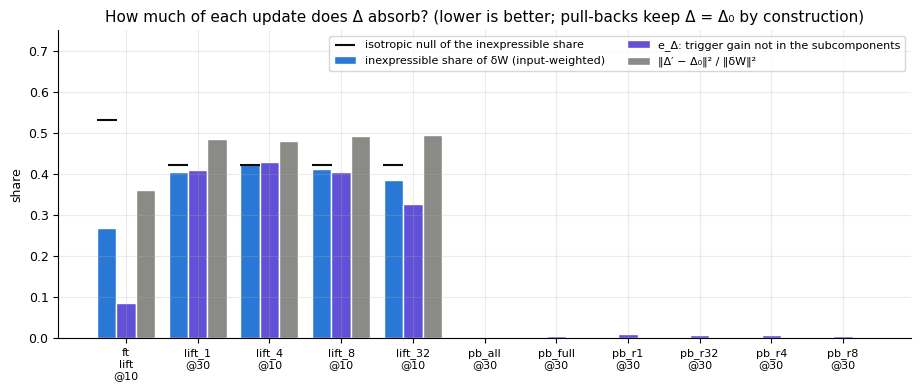

In [3]:
A = scored[~scored.arm.str.contains('nothing')].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(A)); w = 0.27
ax.bar(x - w, A['inexpressible'], w, color=C['blue'], label='inexpressible share of δW (input-weighted)', edgecolor='white')
ax.bar(x, A['e_delta'], w, color=C['violet'], label='e_Δ: trigger gain not in the subcomponents', edgecolor='white')
ax.bar(x + w, A['Delta change'], w, color=C['gray'], label='‖Δ′ − Δ₀‖² / ‖δW‖²', edgecolor='white')
nulls = [L[str(int(a.split('_')[1]))]['steps'][str(s)]['inexpressible']['pooled_null'] if a.startswith('lift') else
         FT['steps'][str(s)]['inexpressible']['pooled_null'] if a == 'ft lift' else np.nan for a, s in zip(A.arm, A.step)]
ax.scatter(x - w, nulls, marker='_', s=200, color='#0b0b0b', label='isotropic null of the inexpressible share', zorder=3)
ax.set_xticks(x); ax.set_xticklabels([f"{a.replace(' ', chr(10))}\n@{s}" for a, s in zip(A.arm, A.step)], fontsize=8)
ax.set_ylabel('share'); ax.set_ylim(0, 0.75)
ax.set_title('How much of each update does Δ absorb? (lower is better; pull-backs keep Δ = Δ₀ by construction)')
ax.legend(ncol=2, loc='upper right'); plt.show()

**Could it do it?** For the LoRA, no better than noise. The LoRA's inexpressible share is 0.38 to 0.43 at every rank against an
isotropic null of 0.42: the LoRA's weight change is no better aligned with the alive subcomponents' read and write spaces than a
random matrix is. Round 2 found the same (0.41 at rank 8, step 10) and its cause: the LoRA's read factor A stays near its random
initialisation (per-row |cos| with init 0.92 to 0.98 at the scored step, 0.67 to 0.96 at step 100 by rank), while the full
fine-tune's update, trained from the model's own gradient on every matrix, is half as inexpressible (0.27 against a null of 0.53).
By step 100 the LoRA's share falls to 0.30 to 0.34, still 1.5× W₀'s own 0.21 on this matrix (round 2).

The lifted LoRA leaves **e_Δ = 0.33 to 0.43** of the behaviour outside the subcomponents (components alone give P(o) 0.74 to 0.95
against the model's 0.97 to 0.999), where the full-weight lift leaves 0.085 (components alone 0.998). Half of the LoRA's Frobenius
mass ends in Δ (0.48 to 0.50) against 0.36 for the full fine-tune. On this reading **the LoRA is harder to decompose than the full
fine-tune, not easier**, and the reason is structural: a LoRA on one matrix has nothing to do with that matrix's decomposition, and
its random read side guarantees half of it lands in the obstruction. The lifts and the do-nothing arms are the same model with the
same weights; the lift moves the subcomponents and Δ, and the do-nothing arm leaves them. Both read 1.4 to 2.0 under the adversary.

**Against the prediction.** P1 (the rank-1 lift has e_Δ ≤ 0.2) is *null* on this clause (0.41). P2's second clause (the
inexpressible share grows with rank) is null (0.40, 0.43, 0.41, 0.38). Both bear on reading A.

## 3. Reading A, task-local: the window adversary at the trigger, against the W₀ floor

The user asked for the task-local PGD ratio against the W₀ floor to be read first. The W₀ floor was measured in this run under three
adversary seeds: `pgd_trigger` KL at the trigger 46.5 / 40.6 / 56.8 nats (max/min 1.40), `pgd_all` 30.0 / 32.4 / 22.4 (1.44). Each
arm's ratio is its KL at the trigger ÷ W₀'s at seed 0 (same seed). The band is the W₀ seed spread.

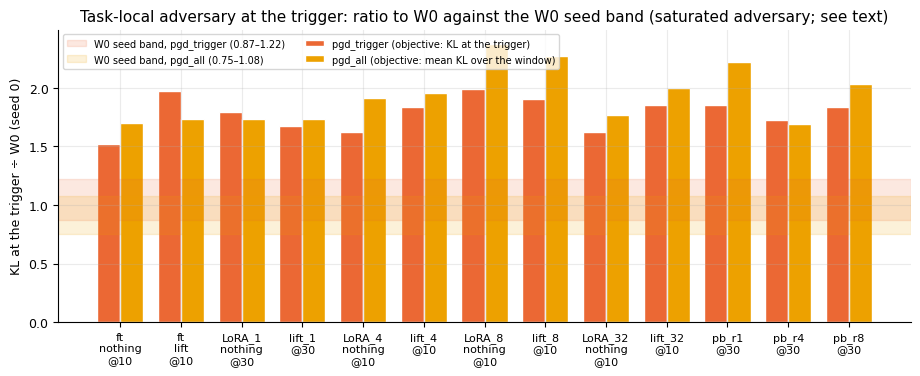

W0 KL at the trigger under pgd_trigger, by seed: {'0': 46.5, '1': 40.6, '2': 56.8}


In [4]:
Lc = scored[scored['local pgd_trigger'].notna()].reset_index(drop=True)
ws = res['w0_local_seeds']['per_seed']; b0 = W0['base']
band = {k: (min(ws[s][k]['kl_trigger'] for s in ws) / b0[k]['kl_trigger'], max(ws[s][k]['kl_trigger'] for s in ws) / b0[k]['kl_trigger']) for k in ('pgd_trigger', 'pgd_all')}
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(Lc)); w = 0.38
ax.bar(x - w/2, Lc['local pgd_trigger'], w, color=C['orange'], label='pgd_trigger (objective: KL at the trigger)', edgecolor='white')
ax.bar(x + w/2, Lc['local pgd_all'], w, color=C['yellow'], label='pgd_all (objective: mean KL over the window)', edgecolor='white')
ax.axhspan(*band['pgd_trigger'], color=C['orange'], alpha=0.15, label=f"W0 seed band, pgd_trigger ({band['pgd_trigger'][0]:.2f}–{band['pgd_trigger'][1]:.2f})")
ax.axhspan(*band['pgd_all'], color=C['yellow'], alpha=0.15, label=f"W0 seed band, pgd_all ({band['pgd_all'][0]:.2f}–{band['pgd_all'][1]:.2f})")
ax.set_xticks(x); ax.set_xticklabels([f"{a.replace(' ', chr(10))}\n@{s}" for a, s in zip(Lc.arm, Lc.step)], fontsize=8)
ax.set_ylabel('KL at the trigger ÷ W0 (seed 0)')
ax.set_title('Task-local adversary at the trigger: ratio to W0 against the W0 seed band (saturated adversary; see text)')
ax.legend(ncol=2, loc='upper left', fontsize=7); plt.show()
print('W0 KL at the trigger under pgd_trigger, by seed:', {s: round(ws[s]['pgd_trigger']['kl_trigger'], 1) for s in ws})

**Reading.** Every arm reads 1.5 to 2.4 on both objectives, do-nothing and lifted and pulled-back alike, above the W₀ seed band
(0.87 to 1.22). The number does not separate the maps: the LoRA_8 do-nothing (1.99) and lift (1.90) are the same, and so are
`pb_r1` (1.86) and `lift_1` (1.67). The W₀ adversary already reaches 41 to 57 nats at the trigger (`reports/reviews/2026-10-19_review_pgd-local.md`:
the shared window adversary is saturated at W₀, its sign set by the seed), so a 1.5 to 2× ratio on a 46-nat base is a statement
about the adversary's basin on the perturbed model, not about which subcomponents carry `o`. It is reported, as the review recommends,
and not used to score anything; the Pile adversary in section 1 is the one with room to move.

## 4. Mechanism reading: which route does each arm's trigger gain take?

The five shares per arm (they sum to 1). For a do-nothing arm d = i = 0 and e_Δ = 1 by construction, so its r (the frozen Γ gating
the unchanged subcomponents differently on the new activations) appears with e_gate = −r. This is the reading the filed P1, P2, P4,
C1 and C3 name (the direct share d); per the user it is a mechanism reading, not the pass criterion.

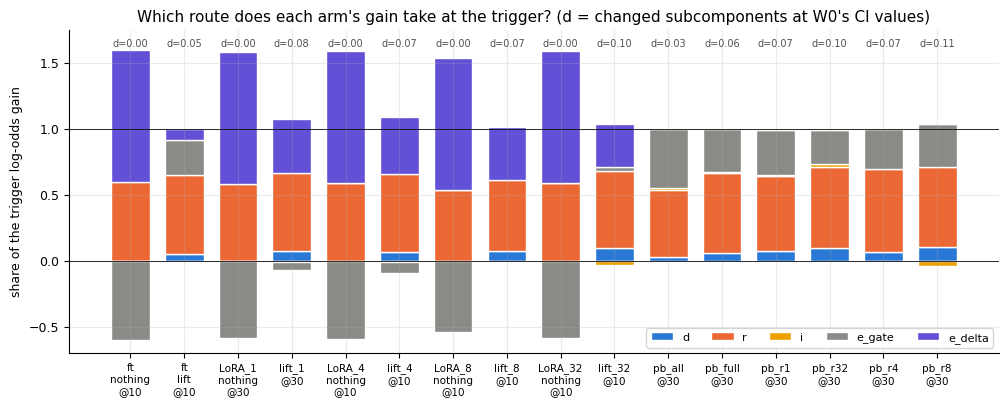

In [5]:
Rs = scored.reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(len(Rs)); pos = np.zeros(len(Rs)); neg = np.zeros(len(Rs))
for k, col in (('d', C['blue']), ('r', C['orange']), ('i', C['yellow']), ('e_gate', C['gray']), ('e_delta', C['violet'])):
    v = Rs[k].values
    bottom = np.where(v >= 0, pos, neg)
    ax.bar(x, v, 0.72, bottom=bottom, color=col, label=k, edgecolor='white', linewidth=1)
    pos += np.where(v >= 0, v, 0); neg += np.where(v < 0, v, 0)
for i, v in enumerate(Rs['d']):
    ax.text(x[i], 1.62, f'd={v:.2f}', ha='center', fontsize=7, color='#52514e')
ax.axhline(1, color='#0b0b0b', lw=0.6); ax.axhline(0, color='#0b0b0b', lw=0.6)
ax.set_xticks(x); ax.set_xticklabels([f"{a.replace(' ', chr(10))}\n@{s}" for a, s in zip(Rs.arm, Rs.step)], fontsize=7.5, rotation=0)
ax.set_ylabel('share of the trigger log-odds gain'); ax.set_ylim(-0.7, 1.75)
ax.set_title('Which route does each arm\'s gain take at the trigger? (d = changed subcomponents at W0\'s CI values)')
ax.legend(ncol=5, loc='lower right'); plt.show()

**Reading.** The direct share is small for every arm: d = 0.05 to 0.11, LoRA or full fine-tune, lift or pull-back, one matrix
or 24. The re-gating share r is 0.51 to 0.63 for every arm, the same for a do-nothing placement as for its lift (r is set by the
update and the task, as the recruit test and the ladder found). What differs between maps is where the rest goes: into e_Δ for the
lifts (0.33 to 0.43 for the LoRA, 0.085 for the full fine-tune) and into e_gate for the pull-backs (0.26 to 0.44: the trained
subcomponents are ones Γ masks off at the trigger).

**Against the predictions.** P1 (d ≥ 0.5 at rank 1) *null* (0.077). P2 (d falls with rank) *null* (0.077, 0.067, 0.072, 0.098: flat
within m = 0.115). P4 (confined pull-back d ≥ 0.3) *neither* (0.07 to 0.11, above the 0.1 null line at ranks 8 and 32 only).
C1 (LoRA lift's d exceeds the full-weight lift's by m) *neither* (0.072 vs 0.053). C3 (one-matrix pull-back's d exceeds the
all-matrix one's by m) *neither* (0.057 vs 0.031). P5 (the lift and the pull-back move the same subcomponents): *null*, as
predicted: 1 of the top 20 by ‖Δ(u vᵀ)‖ is shared; both move nearly every alive subcomponent of the matrix (lift 340/358, pull-back
358/358 by more than 1% of ‖u vᵀ‖), the full-weight lift 2757 of 9881.

## 5. Does anything get worse with rank?

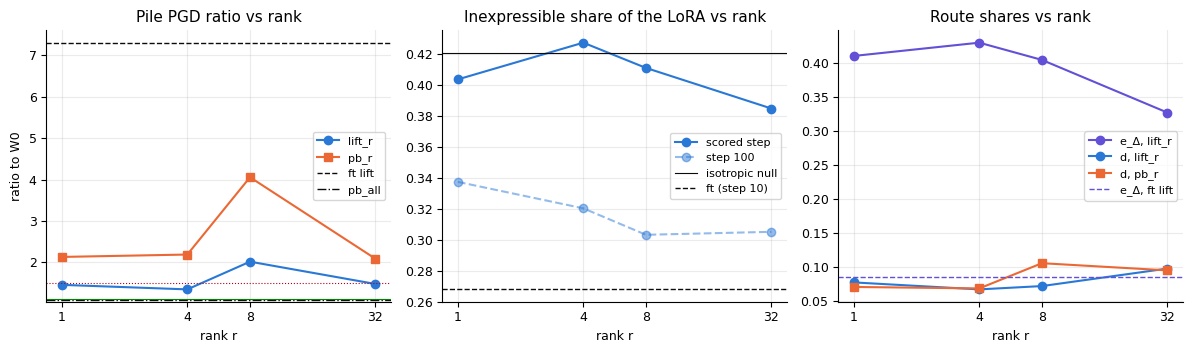

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
ranks = S['ranks']
def series(f): return [f(r) for r in ranks]
ax = axes[0]
ax.plot(ranks, series(lambda r: lora_rec(r)['lift']['pile']['pgd_kl']), 'o-', color=C['blue'], label='lift_r')
ax.plot(ranks, series(lambda r: PB[f'pb_r{r}']['steps']['30']['pile']['pgd_kl']), 's-', color=C['orange'], label='pb_r')
ax.axhline(FT['steps']['10']['lift']['pile']['pgd_kl'], ls='--', color='#0b0b0b', lw=1, label='ft lift')
ax.axhline(PB['pb_all']['steps']['30']['pile']['pgd_kl'], ls='-.', color='#0b0b0b', lw=1, label='pb_all')
ax.axhline(1.5, color='#b00020', lw=0.8, ls=':'); ax.axhline(FLOOR, color=C['green'], lw=0.8)
ax.set_title('Pile PGD ratio vs rank'); ax.set_ylabel('ratio to W0'); ax.legend()
ax = axes[1]
ax.plot(ranks, series(lambda r: lora_rec(r)['inexpressible']['pooled']), 'o-', color=C['blue'], label='scored step')
ax.plot(ranks, series(lambda r: lora_rec(r, 100)['inexpressible']['pooled']), 'o--', color=C['blue'], alpha=0.5, label='step 100')
ax.axhline(lora_rec(8)['inexpressible']['pooled_null'], color='#0b0b0b', lw=0.8, label='isotropic null')
ax.axhline(FT['steps']['10']['inexpressible']['pooled'], ls='--', color='#0b0b0b', lw=1, label='ft (step 10)')
ax.set_title('Inexpressible share of the LoRA vs rank'); ax.legend()
ax = axes[2]
ax.plot(ranks, series(lambda r: lora_rec(r)['lift']['routes']['shares']['e_delta']), 'o-', color=C['violet'], label='e_Δ, lift_r')
ax.plot(ranks, series(lambda r: lora_rec(r)['lift']['routes']['shares']['d']), 'o-', color=C['blue'], label='d, lift_r')
ax.plot(ranks, series(lambda r: PB[f'pb_r{r}']['steps']['30']['routes']['shares']['d']), 's-', color=C['orange'], label='d, pb_r')
ax.axhline(FT['steps']['10']['lift']['routes']['shares']['e_delta'], ls='--', color=C['violet'], lw=1, label='e_Δ, ft lift')
ax.set_title('Route shares vs rank'); ax.legend()
for ax in axes:
    ax.set_xscale('log', base=2); ax.set_xticks(ranks); ax.set_xticklabels([str(r) for r in ranks]); ax.set_xlabel('rank r')
plt.tight_layout(); plt.show()

**Reading.** Nothing orders with rank. The rank-1 LoRA is not "one subcomponent's worth" of update in any measured sense: its
inexpressible share, e_Δ, d and PGD ratio are those of rank 32. The only rank effect is on the rank-constrained pull-back's
fragility (4.1 at rank 8 against 2.1 to 2.2 at the other ranks), within what the ±35% reproduction miss allows. The realised rank of
the rank-r pull-back's weight change is 2r (99% of its energy in the top r singular values for r ≥ 4, 72% for r = 1), as the
construction dU Vᵀ + U dVᵀ implies.

## 6. Scores as filed, and which reading each bears on

`predictions.json` is unchanged. m = 0.115 (G0); every prediction's arms learned and passed G2, so all are scored; the G4 miss on the
full-weight lift's PGD ratio is carried as a caveat on every PGD number.

In [7]:
verdict = lambda p: 'pass' if p['pass'] else ('null' if p['null'] else 'neither')
reading = {'P1': 'A (e_Δ clause); mechanism (d clause)', 'P2': 'A (inexpressible clause); mechanism (d clause)', 'P3': 'A',
           'P4': 'mechanism', 'P5': 'mechanism', 'C1': 'mechanism', 'C2': 'A', 'C3': 'mechanism'}
filed = {p['id'].split('_')[0]: p['predicted'] for p in pred['predictions']}
rows = []
for k in ('P1', 'P2', 'P3', 'P4', 'P5', 'C1', 'C2', 'C3'):
    p = SC[k]
    nums = {kk: (round(vv, 3) if isinstance(vv, float) else vv) for kk, vv in p.items() if kk not in ('pass', 'null', 'scored', 'conditions')}
    rows.append({'prediction': k, 'filed': filed[k], 'result': verdict(p), 'scored': p['scored'], 'bears on': reading[k], 'numbers': str(nums)[:120]})
pd.DataFrame(rows).set_index('prediction')

,filed,result,scored,bears on,numbers
prediction,,,,,
P1,pass,null,True,A (e_Δ clause); mechanism (d clause),"{'d': 0.077, 'e_delta': 0.41}"
P2,pass,null,True,A (inexpressible clause); mechanism (d clause),"{'d': {'1': 0.07734611886098232, '32': 0.09765..."
P3,pass,neither,True,A,"{'limit_3_floors': 1.106, 'pgd_ratio': {'1': 1..."
P4,pass (the most likely to fail),neither,True,mechanism,"{'d': {'1': 0.07066948617464867, '32': 0.09467..."
P5,null,null,True,mechanism,{'shared': 1}
C1,pass (the user's instinct),neither,True,mechanism,"{'d_lift_8': 0.072, 'd_lift_ft': 0.053}"
C2,pass (the user's instinct; uncertain),null,True,A,"{'pgd_lift_8': 2.017, 'pgd_lift_ft': 7.31}"
C3,pass,neither,True,mechanism,"{'d_pb_all': 0.031, 'd_pb_full': 0.057}"


**Summary.** Of eight filed predictions, four are null (P1, P2, P5, C2), four are neither (P3, P4, C1, C3) and none pass. On
reading A the answer to the user's question is no: the LoRA is harder to decompose than the full-weight fine-tune on the two
Δ-absorption numbers (inexpressible share at the null; e_Δ 0.33 to 0.43 against 0.085), and no map applied to it is adversarially
faithful (every arm above the W₀ floor of 1.11 under the Pile adversary; the rank-8 lift and the one-matrix pull-backs over the filed 1.5
line, the other lifts 1.35 to 1.48 and unresolved at this harness's noise), though the LoRA lift is less fragile than the
full-weight lift (2.0 vs 7.3).
On the mechanism reading, nothing distinguishes the LoRA from the full fine-tune: d is 0.05 to 0.11 for every arm and the behaviour
runs through re-gating (r 0.5 to 0.6) in every case.

## Not run

- Seeds beyond one repeat (pb_8, LoRA_8), and no Pile measurement on the repeats, so there is no state-level PGD floor; the reproduction of the full-weight lift's PGD ratio on an L40 (the G4 miss).
- LoRAs on other matrices, or on all 24; a LoRA whose read side is trained before the write side (which would remove the
  random-init cause of the inexpressible share); LoRAs at a step size matched to the pull-back's.
- A per-window or budgeted task-local adversary (the window adversary is saturated at W₀).
- The lost per-step curves and task-local numbers of `pb_r32`, `pb_full`, `pb_all` and the seed arms (recovered from the log only
  in summary); the Jaccard overlaps of the switched-on sets (computed on the pod, not in the log).
- Any task other than emoticon.